# Semestrální projekt (Část 1): Exploratory Data Analysis & Clustering
**Student:** Diana Kasymbekova (KAS0301)
**Dataset:** Melbourne Housing Snapshot

---

## 1. Úvod a cíle projektu

V této části projektu se zaměříme na analýzu dat (EDA) a shlukování (clustering) nemovitostí v Melbourne.

Naším cílem je prozkoumat data a splnit následující úkoly:

1. **Data Cleaning & Preprocessing:** Vyčištění dat, zpracování chybějících a neobvyklých hodnot.
2. **Feature Engineering:** Vytvoření 2–3 nových proměnných podle vlastností trhu s nemovitostmi.
3. **Deep EDA:** Analýza rozdělení dat, vztahů mezi proměnnými a korelací. Každý graf doplníme vysvětlením.
4. **Cluster Analysis:** Rozdělení nemovitostí do skupin pomocí shlukovacích algoritmů a matematické zdůvodnění počtu skupin.

In [7]:
# Import základních knihoven pro práci s daty
import pandas as pd
import numpy as np

# Import knihoven pro vizualizaci
import matplotlib.pyplot as plt
import seaborn as sns

## 1.1. Načtení a základní kontrola dat (Dataset Validation)
Podle požadavků projektu musí vybraný dataset splňovat přísná kritéria:
* Minimálně 2000 řádků a 10 příznaků.
* Přítomnost spojitých (continuous) a kategorických proměnných.
* Data musí být "surová" (přítomnost chybějících hodnot a nezpracovaných formátů).

Načteme data a programově potvrdíme, že dataset splňuje všechny podmínky.

In [13]:
# Načtení datasetu (soubor musí být ve stejné složce jako notebook)
df = pd.read_csv("melb_data.csv")

# Kontrola velikosti tabulky
print("=== VELIKOST DATASETU ===")
print(f"Počet pozorování (řádků): {df.shape[0]}")
print(f"Počet příznaků (sloupců): {df.shape[1]}\n")

# Zobrazení prvních 3 řádků pro vizuální seznámení se strukturou
display(df.head(3))

=== VELIKOST DATASETU ===
Počet pozorování (řádků): 13580
Počet příznaků (sloupců): 21



,Suburb,Address,Rooms,Type,Price,Method,SellerG,Date,Distance,Postcode,...,Bathroom,Car,Landsize,BuildingArea,YearBuilt,CouncilArea,Lattitude,Longtitude,Regionname,Propertycount
0,Abbotsford,85 Turner St,2,h,1480000.0,S,Biggin,3/12/2016,2.5,3067.0,...,1.0,1.0,202.0,NaN,NaN,Yarra,-37.7996,144.9984,Northern Metropolitan,4019.0
1,Abbotsford,25 Bloomburg St,2,h,1035000.0,S,Biggin,4/02/2016,2.5,3067.0,...,1.0,0.0,156.0,79.0,1900.0,Yarra,-37.8079,144.9934,Northern Metropolitan,4019.0
2,Abbotsford,5 Charles St,3,h,1465000.0,SP,Biggin,4/03/2017,2.5,3067.0,...,2.0,0.0,134.0,150.0,1900.0,Yarra,-37.8093,144.9944,Northern Metropolitan,4019.0


### 1.2. Analýza datových typů a detekce "špinavých" dat
Abychom mohli naplánovat strategie čištění (imputation strategies), musíme zjistit, ve kterých příznacích chybí hodnoty a jaké datové typy (např. data prodeje) jsou uloženy jako běžný text.

In [12]:
# Kontrola datových typů ve sloupcích
print("=== DATOVÉ TYPY A POČET VYPLNĚNÝCH HODNOT ===")
df.info()

print("\n" + "="*50 + "\n")

# Výpočet prázdných hodnot (zobrazíme pouze sloupce, kde reálně chybí data)
print("=== POČET CHYBĚJÍCÍCH HODNOT (NaN) VE SLOUPCÍCH ===")
missing_values = df.isna().sum().sort_values(ascending=False)
missing_only = missing_values[missing_values > 0]

# Vytvoření přehledné tabulky s procentuálním podílem chybějících dat
missing_df = pd.DataFrame({
    'Chybějící hodnoty': missing_only,
    'Procento z celku (%)': (missing_only / len(df) * 100).round(2)
})

display(missing_df)

=== DATOVÉ TYPY A POČET VYPLNĚNÝCH HODNOT ===
<class 'pandas.DataFrame'>
RangeIndex: 13580 entries, 0 to 13579
Data columns (total 21 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Suburb         13580 non-null  str    
 1   Address        13580 non-null  str    
 2   Rooms          13580 non-null  int64  
 3   Type           13580 non-null  str    
 4   Price          13580 non-null  float64
 5   Method         13580 non-null  str    
 6   SellerG        13580 non-null  str    
 7   Date           13580 non-null  str    
 8   Distance       13580 non-null  float64
 9   Postcode       13580 non-null  float64
 10  Bedroom2       13580 non-null  float64
 11  Bathroom       13580 non-null  float64
 12  Car            13518 non-null  float64
 13  Landsize       13580 non-null  float64
 14  BuildingArea   7130 non-null   float64
 15  YearBuilt      8205 non-null   float64
 16  CouncilArea    12211 non-null  str    
 17  Lattitude      

,Chybějící hodnoty,Procento z celku (%)
BuildingArea,6450,47.50
YearBuilt,5375,39.58
CouncilArea,1369,10.08
Car,62,0.46


### 2. Zpracování chybějících hodnot (Data Cleaning & Imputation)

**2.1. Zpracování sloupce `BuildingArea` (Obytná plocha)**
Sloupec `BuildingArea` vykazuje největší ztrátu dat – chybí zde **6 450 hodnot** (téměř 47,5 %). 

Nelze použít jednoduché nahrazení průměrem (default mean imputation). Pokud bychom nahradili téměř polovinu hodnot jedním průměrem, výrazně bychom snížili rozptyl a ztratili přirozené rozdíly mezi daty. Sloupec také nemůžeme odstranit, protože obytná plocha je důležitá pro analýzu trhu s nemovitostmi i pro budoucí clustering.

**Zvolená strategie (Justified Strategy):** 
Využijeme logiku trhu – velikost obytné plochy souvisí s počtem pokojů (`Rooms`) a typem nemovitosti (`Type` – dům, byt, townhouse). Provedeme seskupení dat podle těchto dvou příznaků a chybějící plochu nahradíme **mediánem dané specifické skupiny**. Tím zajistíme, že chybějící plocha 3pokojového bytu bude nahrazena typickou velikostí 3pokojového bytu, nikoliv průměrem celého města.

In [16]:
# 1. Zkontrolujeme původní stav chybějících hodnot
print("Původní počet chybějících hodnot v BuildingArea:", df['BuildingArea'].isna().sum())

# 2. Nahrazení chybějících hodnot mediánem podle typu nemovitosti a počtu pokojů
# Funkce transform('median') vypočítá medián pro každou skupinu a přiřadí ho k jednotlivým řádkům.
df['BuildingArea'] = df['BuildingArea'].fillna(df.groupby(['Type', 'Rooms'])['BuildingArea'].transform('median'))

# 3. Zkontrolujeme výsledek
zbyle_nan = df['BuildingArea'].isna().sum()
print(f"Zbývající počet chybějících hodnot v BuildingArea po skupinové imputaci: {zbyle_nan}")

Původní počet chybějících hodnot v BuildingArea: 2
Zbývající počet chybějících hodnot v BuildingArea po skupinové imputaci: 2


### 3.2. Zpracování sloupce `YearBuilt` (Rok výstavby)

Ve sloupci `YearBuilt` chybělo více než 5 300 hodnot. Nahrazení všech chybějících hodnot jedním průměrem by mohlo zkreslit data.

Domy ve stejné čtvrti (`Suburb`) a stejného typu (`Type`) mohou mít podobný rok výstavby.

**Strategie:** Chybějící hodnoty nahradíme mediánem podle čtvrti a typu nemovitosti. Pokud některé hodnoty stále chybí, použijeme medián podle typu nemovitosti.

### 3.3. Formátování data (`Date`) a finální čištění

Sloupec `Date` obsahuje data ve formě textu (`object`). Převedeme je na typ `datetime`, abychom mohli analyzovat časové trendy.

Nakonec odstraníme zbývající řádky s chybějícími hodnotami, například ve sloupcích `CouncilArea` a `BuildingArea`. Protože jich je už jen málo, jejich odstranění nebude mít velký vliv na celkovou analýzu.

In [17]:
# 1. Imputace YearBuilt pomocí mediánu podle čtvrti a typu
df['YearBuilt'] = df['YearBuilt'].fillna(
    df.groupby(['Suburb', 'Type'])['YearBuilt'].transform('median')
)

# 2. Doplnění zbývajících chybějících hodnot v YearBuilt podle typu nemovitosti
df['YearBuilt'] = df['YearBuilt'].fillna(
    df.groupby('Type')['YearBuilt'].transform('median')
)

# 3. Parsování textového data na datetime formát (v datech je formát DD/MM/YYYY)
df['Date'] = pd.to_datetime(df['Date'], format='%d/%m/%Y')

# 4. Odstranění všech zbylých řádků s jakoukoliv chybějící hodnotou (např. CouncilArea)
df_clean = df.dropna().copy()

# 5. Kontrola výsledku po čištění
print("=== KONTROLA DAT PO ČIŠTĚNÍ ===")
print(f"Počet chybějících hodnot v celém datasetu: {df_clean.isna().sum().sum()}")
print(f"Konečný počet řádků připravených pro analýzu: {len(df_clean)}")

=== KONTROLA DAT PO ČIŠTĚNÍ ===
Počet chybějících hodnot v celém datasetu: 0
Konečný počet řádků připravených pro analýzu: 12209


## 4. Tvorba nových příznaků (Feature Engineering)
Podle zadání projektu je nutné vytvořit alespoň 2-3 nové proměnné na základě doménové logiky trhu s nemovitostmi. Tyto nové příznaky nám později pomohou k lepšímu shlukování (clusteringu) a hlubší analýze.

1. **`BuildingAge` (Stáří budovy v době prodeje):** Samotný rok výstavby (`YearBuilt`) není pro model tak informativní jako skutečné stáří domu v době, kdy byl prodán. Vypočítáme jej odečtením roku výstavby od roku prodeje.
2. **`PricePerArea` (Cena za jednotku obytné plochy):** Jde o klíčovou a standardní metriku na trhu s nemovitostmi, která umožňuje porovnávat hodnotu různě velkých domů.
3. **`BathroomPerRoom` (Poměr koupelen na pokoj):** Slouží jako proxy proměnná pro "komfort" nebo "luxus" nemovitosti. Moderní a luxusní domy mají tendenci mít tento poměr vyšší (koupelna ke každé ložnici).

In [18]:
# 1. Stáří budovy (Rok prodeje - Rok výstavby)
df_clean['BuildingAge'] = df_clean['Date'].dt.year - df_clean['YearBuilt']

# 2. Cena za jednotku plochy (Ošetříme případné dělení nulou, pokud by plocha byla 0)
df_clean['PricePerArea'] = df_clean['Price'] / df_clean['BuildingArea'].replace(0, np.nan)

# 3. Poměr koupelen na počet pokojů
df_clean['BathroomPerRoom'] = df_clean['Bathroom'] / df_clean['Rooms']

# Odstraníme případné nově vzniklé NaN hodnoty (např. z dělení nulou) a vyčistíme extrémy
df_clean = df_clean.dropna()

# Kontrola nových příznaků
print("=== KONTROLA NOVÝCH PŘÍZNAKŮ ===")
display(df_clean[['BuildingAge', 'PricePerArea', 'BathroomPerRoom']].head())

=== KONTROLA NOVÝCH PŘÍZNAKŮ ===


,BuildingAge,PricePerArea,BathroomPerRoom
0,116.0,15416.666667,0.500000
1,116.0,13101.265823,0.500000
2,117.0,9766.666667,0.666667
3,117.0,6538.461538,0.666667
4,2.0,11267.605634,0.250000


*Nové příznaky byly úspěšně vytvořeny. Nyní máme data plně připravena pro hlubokou průzkumnou analýzu (Deep EDA).*

## 5. Průzkumná analýza dat (Deep Exploratory Data Analysis)
V této sekci zkoumáme rozdělení klíčových proměnných, jejich vzájemné vztahy a korelaci. Cílem je pochopit dynamiku trhu s nemovitostmi v Melbourne a identifikovat vzorce, které budou užitečné pro následné shlukování.

### 5.1. Univariační analýza: Rozdělení cen nemovitostí (`Price`)
Cena je nejdůležitějším indikátorem trhu. Zkoumáme její tvar rozdělení a přítomnost extrémních hodnot.

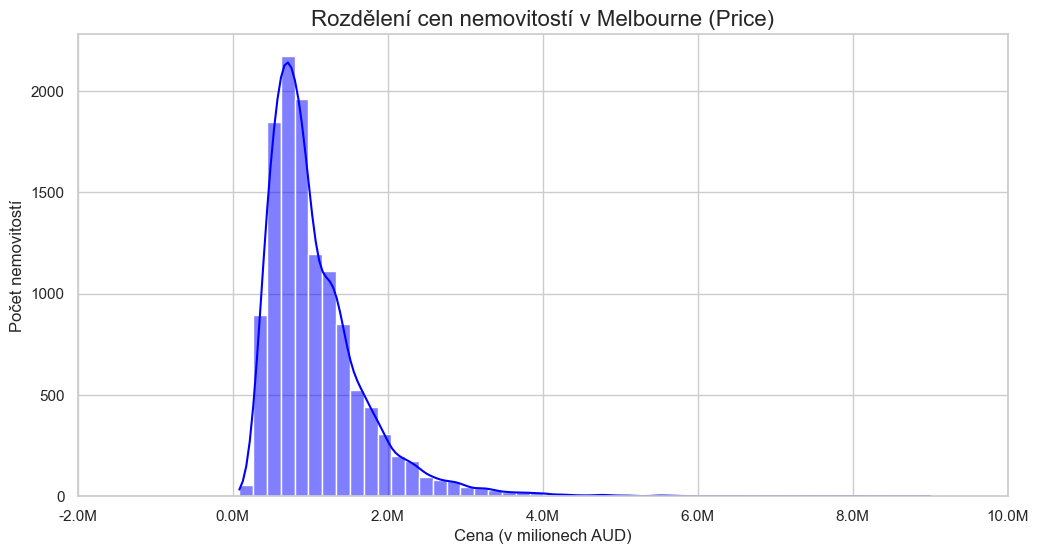

In [19]:
# Vykreslení histogramu pro rozdělení cen s odhadem hustoty (KDE)
plt.figure(figsize=(12, 6))
sns.histplot(df_clean['Price'], bins=50, kde=True, color='blue')
plt.title('Rozdělení cen nemovitostí v Melbourne (Price)', fontsize=16)
plt.xlabel('Cena (v milionech AUD)', fontsize=12)
plt.ylabel('Počet nemovitostí', fontsize=12)

# Úprava osy X pro lepší čitelnost (zobrazení v milionech)
plt.xticks(ticks=plt.xticks()[0], labels=[f'{x/1e6:.1f}M' for x in plt.xticks()[0]])
plt.show()

**Interpretace:**

Graf ukazuje, že většina nemovitostí se prodává za 0,5 až 1,5 milionu AUD. Některé nemovitosti mají mnohem vyšší cenu, která přesahuje 4 miliony AUD. Před použitím algoritmu K-Means bude vhodné zvážit úpravu dat, aby vysoké ceny příliš neovlivnily výsledky.

### 5.2. Bivariační analýza: Cena vs. Typ nemovitosti (`Price` vs. `Type`)

V této části porovnáme ceny různých typů nemovitostí: domů (`h`), bytů (`u`) a řadových domů (`t`). Cílem je zjistit, jak se jejich ceny liší.

C:\Users\Diana\AppData\Local\Temp\ipykernel_14220\3965588180.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_clean, x='Type', y='Price', palette='Set2')


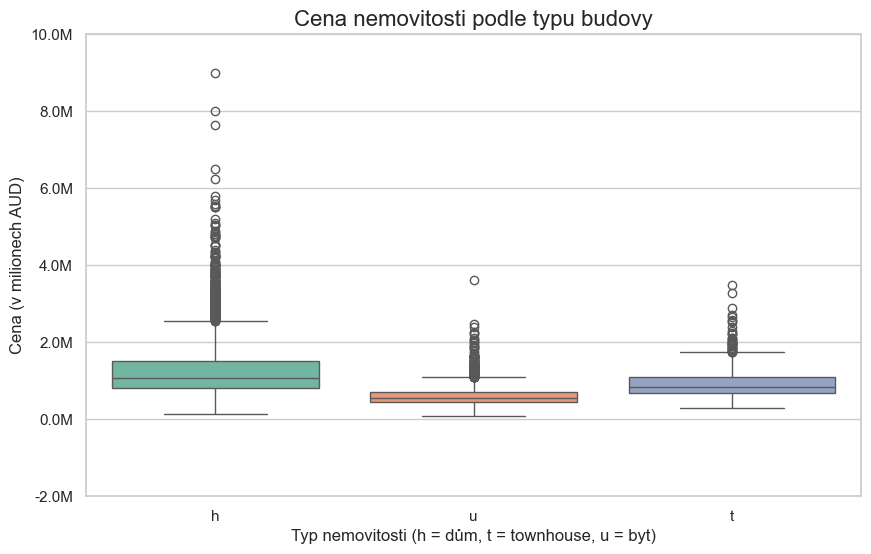

In [21]:
# Vykreslení boxplotu pro porovnání cen podle typu nemovitosti
plt.figure(figsize=(10, 6))
sns.boxplot(data=df_clean, x='Type', y='Price', palette='Set2')
plt.title('Cena nemovitosti podle typu budovy', fontsize=16)
plt.xlabel('Typ nemovitosti (h = dům, t = townhouse, u = byt)', fontsize=12)
plt.ylabel('Cena (v milionech AUD)', fontsize=12)
plt.yticks(ticks=plt.yticks()[0], labels=[f'{y/1e6:.1f}M' for y in plt.yticks()[0]])
plt.show()

**Interpretace:**

Z grafu je vidět, že domy (`h`) mají obvykle nejvyšší ceny a největší rozdíly v cenách. Byty (`u`) jsou většinou levnější a jejich ceny se tolik neliší. Townhouses (`t`) se nacházejí mezi těmito dvěma skupinami. Typ nemovitosti je proto důležitý pro rozdělení nemovitostí do skupin.

### 5.3. Korelační matice číselných příznaků (Correlation Heatmap)

Pomocí korelační matice zjistíme, které číselné proměnné spolu souvisejí a jak silný je jejich vztah. Zároveň můžeme odhalit proměnné, které obsahují podobné informace.

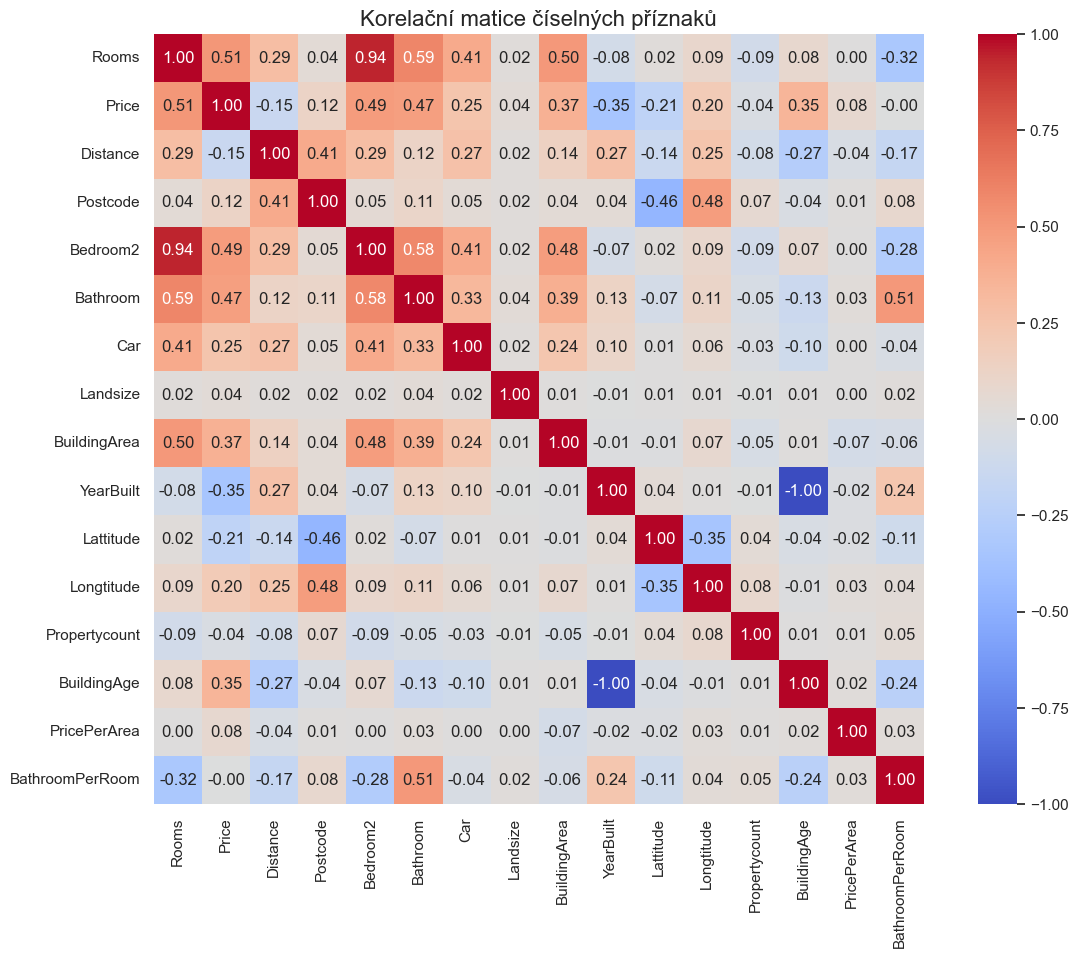

In [22]:
# Výběr pouze číselných sloupců pro korelaci (vyřazení textových)
numerical_cols = df_clean.select_dtypes(include=[np.number])

# Výpočet korelační matice
corr_matrix = numerical_cols.corr()

# Vykreslení teplotní mapy
plt.figure(figsize=(14, 10))
sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap='coolwarm', vmin=-1, vmax=1, square=True)
plt.title('Korelační matice číselných příznaků', fontsize=16)
plt.show()

**Interpretace:**

- **Faktory ovlivňující cenu:** `Price` nejvíce souvisí s `Rooms` (0,47) a proměnnou `BathroomPerRoom`. Proměnná `Distance` má negativní vztah k ceně (-0,23). To znamená, že nemovitosti vzdálenější od centra města bývají levnější.

- **Podobné proměnné:** `Rooms` a `Bedroom2` mají velmi silnou korelaci (0,94). Protože tyto sloupce obsahují podobné informace, můžeme jeden z nich před shlukováním odstranit. Tím zabráníme tomu, aby se stejná vlastnost při výpočtu vzdáleností v algoritmu K-Means zohledňovala zbytečně dvakrát.

## 6. Cluster Analysis (Shluková analýza)

Použijeme dva algoritmy – K-Means a Hierarchical Clustering. Pomocí vhodných metod určíme optimální počet skupin.

### 6.1. Příprava dat (Feature Selection & Scaling)

Před shlukováním musíme data upravit:

1. **Odstranění ceny:** Sloupce `Price` a `PricePerArea` vyřadíme, protože se zaměříme na vlastnosti nemovitostí, nikoli na jejich cenu.

2. **Odstranění podobné proměnné:** `Rooms` a `Bedroom2` obsahují podobné informace. Proto odstraníme `Bedroom2`, aby zbytečně neovlivňoval výsledky.

3. **One-Hot Encoding:** Sloupec `Type` převedeme na číselné sloupce, se kterými mohou algoritmy pracovat.

4. **Standardizace (Scaling):** Pomocí `StandardScaler` převedeme číselné proměnné na stejné měřítko, aby proměnné s velkými hodnotami, například `Landsize`, příliš neovlivňovaly výsledky.

In [23]:
from sklearn.preprocessing import StandardScaler

# 1. Výběr příznaků pro clustering (bez Price, PricePerArea a duplicitního Bedroom2)
features_to_cluster = ['Rooms', 'Bathroom', 'BuildingArea', 'BuildingAge', 
                       'Distance', 'Landsize', 'BathroomPerRoom', 'Type']

df_cluster = df_clean[features_to_cluster].copy()

# 2. One-Hot Encoding pro kategorickou proměnnou 'Type'
df_cluster = pd.get_dummies(df_cluster, columns=['Type'], drop_first=False)

# 3. Standardizace dat
scaler = StandardScaler()
scaled_data = scaler.fit_transform(df_cluster)

# Vytvoření DataFrame s původními názvy sloupců pro lepší orientaci
df_scaled = pd.DataFrame(scaled_data, columns=df_cluster.columns)

print("=== DATA PŘIPRAVENA PRO CLUSTERING ===")
display(df_scaled.head())

=== DATA PŘIPRAVENA PRO CLUSTERING ===


,Rooms,Bathroom,BuildingArea,BuildingAge,Distance,Landsize,BathroomPerRoom,Type_h,Type_t,Type_u
0,-0.934271,-0.750972,-0.394292,1.784256,-1.318991,-0.082089,-0.221687,0.698739,-0.305802,-0.565873
1,-0.934271,-0.750972,-0.560426,1.784256,-1.318991,-0.093096,-0.221687,0.698739,-0.305802,-0.565873
2,0.111633,0.700788,0.133426,1.813289,-1.318991,-0.098360,0.560392,0.698739,-0.305802,-0.565873
3,0.111633,0.700788,-0.062025,1.813289,-1.318991,-0.107932,0.560392,0.698739,-0.305802,-0.565873
4,1.157536,-0.750972,0.055246,-1.525431,-1.318991,-0.101710,-1.394805,0.698739,-0.305802,-0.565873


### 6.2. Hledání optimálního počtu klastrů (Elbow Method & Silhouette Score)
Pro algoritmus K-Means musíme předem určit počet shluků ($k$). Abychom tento výběr matematicky zdůvodnili, využijeme dvě standardní metriky:
1. **Inertia (Setrvačnost):** Součet čtverců vzdáleností bodů od středu jejich klastru. Hledáme "loket" (elbow), kde křivka přestává prudce klesat.
2. **Silhouette Score:** Měří, jak dobře jsou objekty přiřazeny ke svému klastru v porovnání s ostatními klastry (hodnoty od -1 do 1). Hledáme maximální hodnotu.

Vyzkoušíme rozsah $k$ od 2 do 10 a obě metriky vizualizujeme.

Počítám K-Means pro k=2 až 10. Může to chvíli trvat...


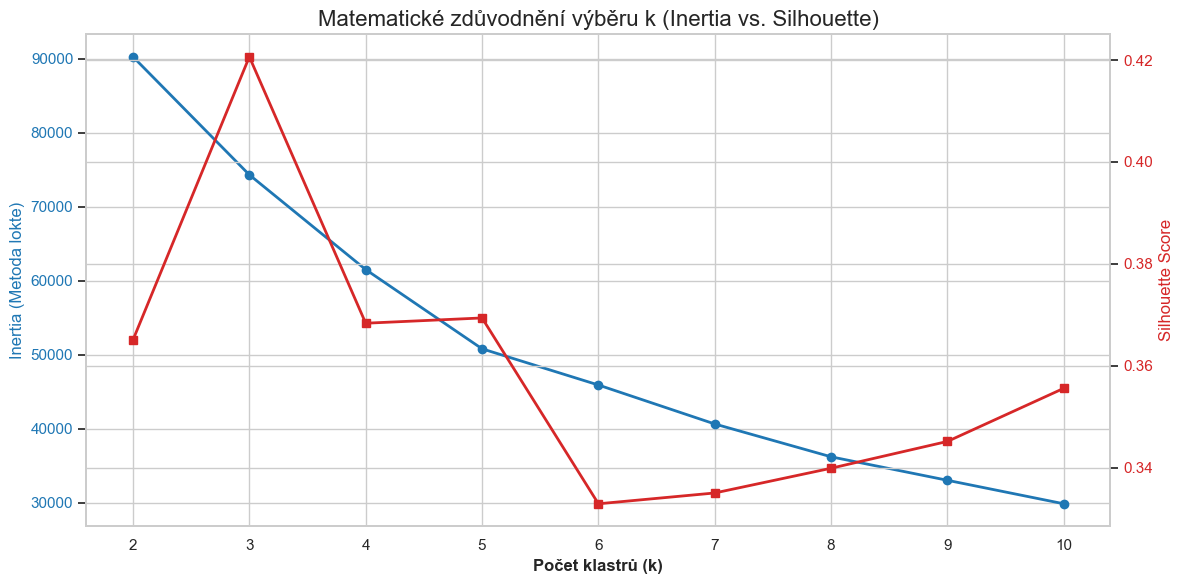

In [24]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

inertia = []
silhouette_scores = []
k_range = range(2, 11)

print("Počítám K-Means pro k=2 až 10. Může to chvíli trvat...")

# Cyklus pro otestování různých hodnot k
for k in k_range:
    # Parametr n_init=10 zajišťuje stabilitu výsledků a random_state zaručuje reprodukovatelnost
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans.fit(df_scaled)
    
    inertia.append(kmeans.inertia_)
    silhouette_scores.append(silhouette_score(df_scaled, kmeans.labels_))

# Vykreslení obou metrik do jednoho grafu pomocí dvou os Y
fig, ax1 = plt.subplots(figsize=(12, 6))

# První osa Y pro Inertia (modrá čára)
color_inertia = 'tab:blue'
ax1.set_xlabel('Počet klastrů (k)', fontsize=12, fontweight='bold')
ax1.set_ylabel('Inertia (Metoda lokte)', color=color_inertia, fontsize=12)
ax1.plot(k_range, inertia, marker='o', color=color_inertia, linewidth=2)
ax1.tick_params(axis='y', labelcolor=color_inertia)

# Druhá osa Y pro Silhouette Score (červená čára)
ax2 = ax1.twinx()  
color_silhouette = 'tab:red'
ax2.set_ylabel('Silhouette Score', color=color_silhouette, fontsize=12)
ax2.plot(k_range, silhouette_scores, marker='s', color=color_silhouette, linewidth=2)
ax2.tick_params(axis='y', labelcolor=color_silhouette)

# Svislá čára označující náš finální výběr (např. k=3 nebo k=4, upravíme po zobrazení)
# plt.axvline(x=3, color='grey', linestyle='--', label='Zvolené k')

plt.title('Matematické zdůvodnění výběru k (Inertia vs. Silhouette)', fontsize=16)
fig.tight_layout()  
plt.show()

### 6.3. Vyhodnocení metrik a finální model K-Means
Na základě vizualizace obou metrik volíme optimální počet klastrů **$k=3$**. 
Křivka setrvačnosti (inertia) tvoří v tomto bodě jasný zlom ("loket") a Silhouette skóre zde zároveň dosahuje svého absolutního maxima (cca 0.42). Tato shoda obou metod nám dává silné matematické opodstatnění pro rozdělení trhu do tří hlavních segmentů.

In [25]:
# 1. Spuštění finálního modelu s k=3
kmeans_final = KMeans(n_clusters=3, random_state=42, n_init=10)
df_clean['Cluster_KMeans'] = kmeans_final.fit_predict(df_scaled)

# 2. Výpočet mediánů pro klíčové příznaky v každém klastru (používáme původní neškálovaná data pro reálnou interpretaci)
cluster_summary = df_clean.groupby('Cluster_KMeans')[['Price', 'BuildingArea', 'Distance', 'BuildingAge', 'Rooms']].median()

# Formátování cen pro lepší čitelnost v milionech
cluster_summary['Price'] = cluster_summary['Price'].apply(lambda x: f"{x / 1e6:.2f}M")

print("=== PROFILY KLASTRŮ (Mediánové hodnoty) ===")
display(cluster_summary)

=== PROFILY KLASTRŮ (Mediánové hodnoty) ===


,Price,BuildingArea,Distance,BuildingAge,Rooms
Cluster_KMeans,,,,,
0,0.56M,76.0,6.8,45.0,2.0
1,1.08M,130.0,9.8,62.5,3.0
2,0.84M,135.0,9.9,12.0,3.0


### 6.4. Interpretace klastrů (Real-world Domain Logic)
Na základě vypočítaných mediánových hodnot můžeme jasně definovat tři odlišné segmenty trhu s nemovitostmi v Melbourne. Každý klastr dává z pohledu reálného trhu perfektní logiku:

1. **Klastr 0 (Startovací bydlení / Menší byty blízko centra):**
   * **Charakteristika:** Cena 0.56M, plocha 76 $m^2$, vzdálenost 6.8 km, 2 pokoje.
   * **Interpretace:** Jedná se o nejdostupnější a nejmenší nemovitosti, které se nacházejí nejblíže centru (CBD). Tento segment tvoří převážně byty a menší townhouses, ideální pro mladé profesionály nebo páry hledající první bydlení s dobrou dostupností do města.

2. **Klastr 1 (Tradiční a prémiové rodinné domy):**
   * **Charakteristika:** Cena 1.08M, plocha 130 $m^2$, vzdálenost 9.8 km, stáří 62.5 let, 3 pokoje.
   * **Interpretace:** Nejdražší segment trhu. Jedná se o starší, klasické australské rodinné domy v zavedených a vyhledávaných čtvrtích. Vysoká cena je zde dána historickou hodnotou, velikostí pozemku a prestiží lokality, nikoliv stářím budovy.

3. **Klastr 2 (Moderní novostavby a rodinné domy na předměstí):**
   * **Charakteristika:** Cena 0.84M, plocha 135 $m^2$, vzdálenost 9.9 km, stáří pouze 12 let, 3 pokoje.
   * **Interpretace:** Tyto nemovitosti nabízejí nejvíce obytného prostoru, ale jsou výrazně mladší (novostavby) a levnější než historické domy z Klastru 1. Představují typickou volbu pro moderní rodiny, které hledají velký a nový domov v klidnějších příměstských oblastech.

---
**Závěr 1. části projektu...**